# Машинное обучение, ПМИ ФКН ВШЭ

## Рекомендательные системы

В этом семинаре будем рекомендовать музыку. Возьмём [Yambda](https://huggingface.co/datasets/yandex/yambda) - это открытые данные о взаимодействиях пользователей Яндекс Музыки с треками. Нам понадобится только небольшой файл лайков из поднабора Yambda-50M.

У нас есть события: пользователь лайкнул трек. На их основе будем предсказывать, какие ещё треки он лайкнет. Начнём со случайных рекомендаций и популярности, затем обучим матричную модель iALS и сравним результаты.

In [1]:
%pip install -q implicit==0.7.3 pyarrow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 33.0 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import scipy.sparse as scs
import matplotlib.pyplot as plt
from implicit.cpu.als import AlternatingLeastSquares
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display
from threadpoolctl import threadpool_limits

SEED = 42
plt.rcParams.update({'font.size': 12})

### Данные

Сначала загрузим данные в формате "паркет". В каждой строке записаны `uid` пользователя, `item_id` трека, время события `timestamp` и признак `is_organic`: возникло ли взаимодействие самостоятельно или через рекомендации сервиса.

Лайк явно выражает интерес, но отсутствие лайка не означает, что трек не понравился: пользователь мог его просто не встретить. Отмены лайков, дизлайки и прослушивания находятся в других файлах бенчмарка, мы в этом ноутбуке их не используем.

In [3]:
data_url = (
    'https://huggingface.co/datasets/yandex/yambda/resolve/'
    '7b1599e64976bef69489e392403da129ab9325c9/flat/50m/likes.parquet'
)
ratings = pd.read_parquet(data_url)
ratings.head()

,uid,timestamp,item_id,is_organic
0,100,44755,732449,1
1,100,1155860,6568592,0
2,100,1259125,5411243,1
3,100,1260005,7371186,0
4,100,1263935,4943655,0


Посмотрим, сколько всего есть лайков, пользователей и треков.

In [4]:
pd.Series({
    'Лайков': len(ratings),
    'Пользователей': ratings['uid'].nunique(),
    'Треков': ratings['item_id'].nunique(),
})

,0
Лайков,881456
Пользователей,8283
Треков,181304


### Разбиение по времени

Возьмём Global Temporal Split из самой [статьи о Yambda](https://arxiv.org/html/2505.22238v2#S4). Авторы оставляют около 300 дней истории для обучения, затем делают перерыв в 30 минут и проверяют рекомендации за один день. Для подбора параметров из обучающей истории выделяют ещё один день, тоже с получасовым перерывом перед ним.

Численные границы тоже берем из оригинального кода авторов: [constants.py](https://huggingface.co/datasets/yandex/yambda/blob/1be89f3cd898aa548c9eec31e0cb9e83b3e90749/benchmarks/yambda/constants.py) и [timesplit.py](https://huggingface.co/datasets/yandex/yambda/blob/1be89f3cd898aa548c9eec31e0cb9e83b3e90749/benchmarks/yambda/processing/timesplit.py). `timestamp` измеряется в секундах от начала периода, с точностью до пяти секунд.

Мы хоть и повторяем логику, но работать будем с малой частью бенча. А считаем MAP@20 и Recall@20 для новых треков в этом каталоге.

In [5]:
DAY = 24 * 60 * 60
GAP = 30 * 60
LAST_TIMESTAMP = 26_000_000

test_start = LAST_TIMESTAMP - DAY
valid_end = test_start - GAP
valid_start = valid_end - DAY
train_end = valid_start - GAP

train_raw = ratings[ratings['timestamp'] < train_end].copy()
valid_raw = ratings[ratings['timestamp'].between(valid_start, valid_end, inclusive='left')].copy()
test_raw = ratings[ratings['timestamp'].between(test_start, LAST_TIMESTAMP, inclusive='left')].copy()

# после подбора параметров используем всю историю до получасового перерыва перед тестом
final_train_raw = ratings[ratings['timestamp'] < valid_end].copy()

pd.DataFrame({
    'Часть': ['Обучение для подбора', 'Перерыв', 'Валидация', 'Перерыв', 'Тест'],
    'От, секунд': [0, train_end, valid_start, valid_end, test_start],
    'До, не включая': [train_end, valid_start, valid_end, test_start, LAST_TIMESTAMP],
    'Событий': [
        len(train_raw),
        ratings['timestamp'].between(train_end, valid_start, inclusive='left').sum(),
        len(valid_raw),
        ratings['timestamp'].between(valid_end, test_start, inclusive='left').sum(),
        len(test_raw),
    ],
})

,Часть,"От, секунд","До, не включая",Событий
0,Обучение для подбора,0,25823600,872573
1,Перерыв,25823600,25825400,40
2,Валидация,25825400,25911800,4512
3,Перерыв,25911800,25913600,52
4,Тест,25913600,26000000,4279


### Посмотрим на данные

Начнём со всей обучающей части, пока ещё не ограничивали число пользователей и треков. Сколько в ней пропусков и повторных лайков? Насколько заполнена матрица взаимодействий? События повторного лайка пока не удаляем: они нужны для подсчёта активности, а при построении матрицы каждую пару учтём один раз.

In [6]:
eda_pairs = train_raw[['uid', 'item_id']].drop_duplicates()
display(pd.Series({
    'Событий лайка': len(train_raw),
    'Различных пар пользователь-трек': len(eda_pairs),
    'Повторных пар': len(train_raw) - len(eda_pairs),
    'Пользователей': eda_pairs['uid'].nunique(),
    'Треков': eda_pairs['item_id'].nunique(),
    'Строк с пропусками': train_raw.isna().any(axis=1).sum(),
}))
print(f"Заполнено {len(eda_pairs) / (eda_pairs['uid'].nunique() * eda_pairs['item_id'].nunique()):.4%} матрицы.")

,0
Событий лайка,872573
Различных пар пользователь-трек,836152
Повторных пар,36421
Пользователей,8269
Треков,180239
Строк с пропусками,0


Заполнено 0.0561% матрицы.


Посмотрим, одинаково ли часто пользователи ставят лайки в разные дни. День считаем от начала периода в датасете. Последний неполный день не рисуем, чтобы его короткая продолжительность не выглядела как спад активности.

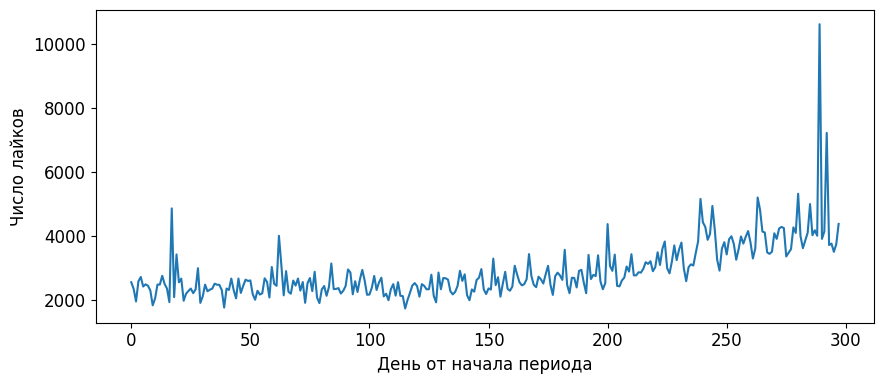

In [7]:
daily_likes = train_raw.groupby(train_raw['timestamp'] // DAY).size()
daily_likes = daily_likes.reindex(np.arange(train_end // DAY), fill_value=0)

plt.figure(figsize=(9, 4))
plt.plot(daily_likes.index, daily_likes.values)
plt.xlabel('День от начала периода')
plt.ylabel('Число лайков')
plt.tight_layout()
plt.show()

Ещё один полезный признак - `is_organic`. Сравним доли лайков, поставленных самостоятельно и через рекомендации сервиса.

Если понимание, почему это признак имеет значение?

> Рекомендательная система сама влияет на данные, на которых потом учится. Треки, которые она чаще показывает, получают больше шансов на прослушивание и лайк. Эти взаимодействия попадают в следующую обучающую выборку, и модель получает подтверждение: такие треки стоит рекомендовать ещё чаще.
>
> Вот и возникает **петля обратной связи aka [feedback loop](https://arxiv.org/abs/1710.11214)**: рекомендации влияют на поведение пользователей, а это поведение определяет следующие рекомендации. В результате система может не столько узнавать что-то новое о вкусах пользователей, сколько закреплять собственные предыдущие решения.
>
> Признак `is_organic` позволяет хотя бы разделить взаимодействия по тому, как пользователь пришёл к треку. Cравнение долей здесь это повод обсудить, как сформировались наши данные, а не способ само по себе доказать или устранить такую петлю.

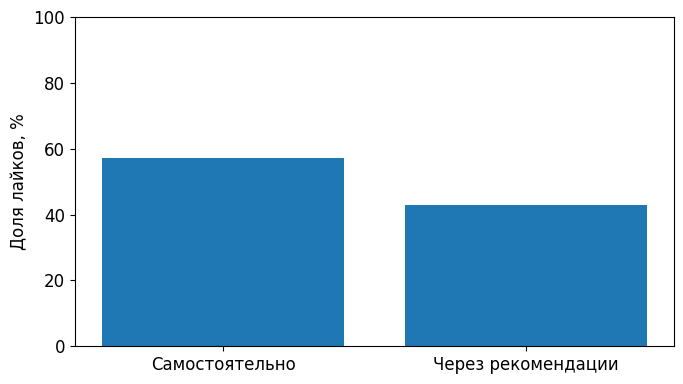

In [8]:
organic_share = train_raw['is_organic'].value_counts(normalize=True).reindex([1, 0], fill_value=0)

plt.figure(figsize=(7, 4))
plt.bar(['Самостоятельно', 'Через рекомендации'], organic_share.to_numpy() * 100)
plt.ylabel('Доля лайков, %')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

Насколько сильно лайки сосредоточены на популярных треках? Упорядочим треки по числу пользователей и посчитаем накопленную долю лайков. Для каждого пользователя один трек учитываем один раз. Такой график помогает понять, почему даже рекомендации по популярности могут оказаться полезными.

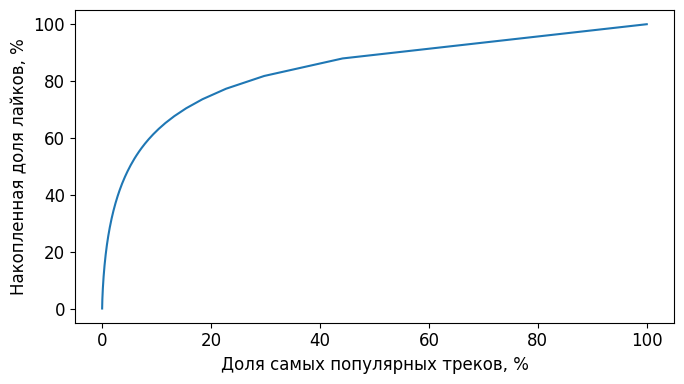

На 1% самых популярных треков приходится 24.0% лайков.


In [9]:
item_popularity = eda_pairs.groupby('item_id').size().sort_values(ascending=False)
item_fraction = np.arange(1, len(item_popularity) + 1) / len(item_popularity)
like_fraction = item_popularity.cumsum().to_numpy() / item_popularity.sum()

plt.figure(figsize=(7, 4))
plt.plot(np.r_[0, item_fraction] * 100, np.r_[0, like_fraction] * 100)
plt.xlabel('Доля самых популярных треков, %')
plt.ylabel('Накопленная доля лайков, %')
plt.tight_layout()
plt.show()
print(f'На 1% самых популярных треков приходится {like_fraction[np.searchsorted(item_fraction, 0.01)]:.1%} лайков.')

Для семинара ограничим каталог 5000 популярными треками, которые лайкнули хотя бы пять пользователей. Из пользователей с пятью и более треками в таком каталоге случайно выберем до 2000. Частоты и длины историй считаем только по обучающей части. Повторные лайки одной пары учитываем один раз.

In [10]:
pairs = train_raw[['uid', 'item_id']].drop_duplicates()
item_counts = pairs.groupby('item_id').size().sort_values(ascending=False, kind='stable')
popular_items = item_counts[item_counts >= 5].head(5_000).index
pairs = pairs[pairs['item_id'].isin(popular_items)]

user_counts = pairs.groupby('uid').size()
eligible_users = user_counts[user_counts >= 5].index.to_numpy()
selected_users = np.random.default_rng(SEED).choice(
    eligible_users, size=min(2_000, len(eligible_users)), replace=False
)
train_ratings = pairs[pairs['uid'].isin(selected_users)].copy()

user_ids = np.sort(train_ratings['uid'].unique())
item_ids = np.sort(train_ratings['item_id'].unique())
num_users, num_items = len(user_ids), len(item_ids)
user_index = pd.Series(np.arange(num_users), index=user_ids)
item_index = pd.Series(np.arange(num_items), index=item_ids)
print(f'В срезе: {num_users} пользователей, {num_items} треков, {len(train_ratings)} лайков.')

В срезе: 2000 пользователей, 5000 треков, 113755 лайков.


Посмотрим на длины пользовательских историй в нашем срезе.

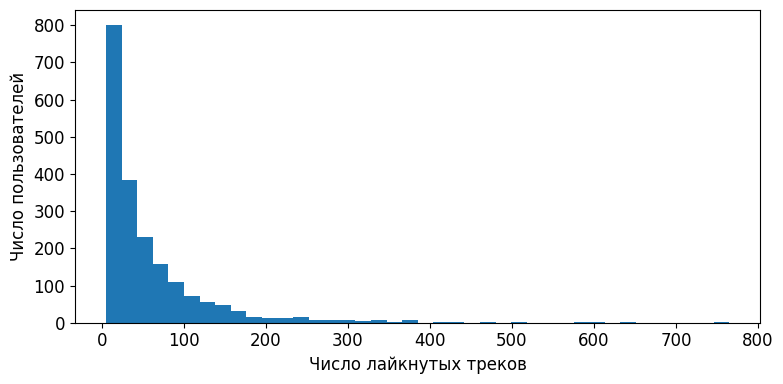

In [11]:
plt.figure(figsize=(8, 4))
plt.hist(train_ratings.groupby('uid').size(), bins=40)
plt.xlabel('Число лайкнутых треков')
plt.ylabel('Число пользователей')
plt.tight_layout()
plt.show()

И на число лайков у разных треков. Логарифмическая шкала помогает увидеть и редкие, и популярные треки на одном графике.

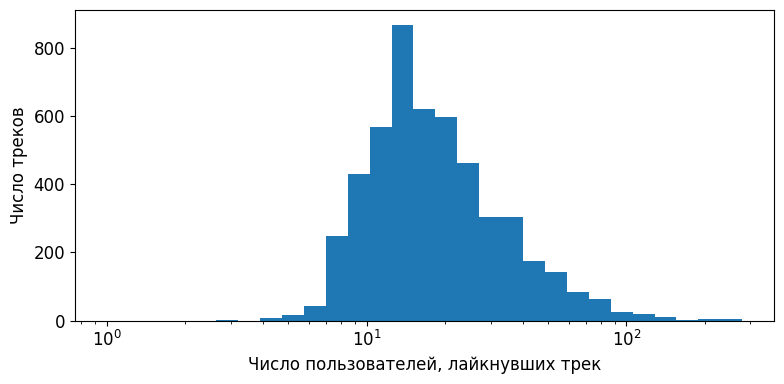

In [12]:
counts = train_ratings.groupby('item_id').size().to_numpy()
plt.figure(figsize=(8, 4))
plt.hist(counts, bins=np.geomspace(1, counts.max() + 1, 30))
plt.xscale('log')
plt.xlabel('Число пользователей, лайкнувших трек')
plt.ylabel('Число треков')
plt.tight_layout()
plt.show()

### Матрица взаимодействий

Теперь соберем матрицу интеракций "пользователь × трек": единица означает, что лайк был, ноль - что его не было в нашей истории. Большинство элементов равны нулю, поэтому будем хранить матрицу в разреженном формате CSR.

Исходные идентификаторы заменим номерами строк и столбцов. Соответствие уже задано в `user_index` и `item_index` - используем его для всех частей данных. Пользователей и треки вне обучающего среза в этот пример не включаем.

In [13]:
def make_matrix(events):
    mask = events['uid'].isin(user_ids) & events['item_id'].isin(item_ids)
    pairs = events.loc[mask, ['uid', 'item_id']].drop_duplicates()
    rows = pairs['uid'].map(user_index).to_numpy()
    cols = pairs['item_id'].map(item_index).to_numpy()
    return scs.csr_matrix(
        (np.ones(len(pairs), dtype=np.float32), (rows, cols)),
        shape=(num_users, num_items),
    )


train_matrix = make_matrix(train_ratings)
print(f'Размер матрицы: {train_matrix.shape}')
print(f'Доля ненулевых элементов: {train_matrix.nnz / (num_users * num_items):.3%}')

Размер матрицы: (2000, 5000)
Доля ненулевых элементов: 1.138%


### Оценка качества

Теперь к оценке - мы рекомендуем треки, которых *ещё нет* в истории лайков пользователя. Значит, из отложенных ответов тоже нужно убрать уже известные ему треки. Оценку считаем по пользователям, у которых после этого остался хотя бы один новый лайк в нашем каталоге.

Recall@k показывает, какую долю новых лайков удалось найти. MAP@k учитывает ещё и порядок: попадание в начале списка ценнее попадания в конце.

$$
\operatorname{Recall}_u@k=\frac{\sum_{j=1}^k \operatorname{rel}_u(j)}{|R_u|},
\qquad
AP_u@k=\frac{\sum_{j=1}^k \operatorname{rel}_u(j)\,P_u@j}{\min(k,|R_u|)}.
$$

Здесь $R_u$ - все новые лайки пользователя в выбранном каталоге, $\operatorname{rel}_u(j)$ - признак попадания на позиции $j$, а $P_u@j$ - доля попаданий среди первых $j$ рекомендаций. Усреднив $AP_u@k$ по пользователям, получим MAP@k.

Все модели оцениваем на одних пользователях и полных списках ответов. Не найденные моделью треки из ответов не удаляем; пустая выдача получает ноль.

In [14]:
def make_relevant(events, history):
    targets = make_matrix(events)
    targets = targets - targets.multiply(history)
    targets.eliminate_zeros()
    users = np.flatnonzero(targets.getnnz(axis=1))
    return {user: targets[user].indices for user in users}


def ranking_metrics(relevant, predicted, k=20):
    ap, recall = [], []
    for user, targets in relevant.items():
        items = np.asarray(predicted[user])[:k]
        hits = np.isin(items, targets)
        precision = np.cumsum(hits) / np.arange(1, len(items) + 1)
        ap.append(np.sum(precision * hits) / min(k, len(targets)))
        recall.append(hits.sum() / len(targets))
    return {f'MAP@{k}': np.mean(ap), f'Recall@{k}': np.mean(recall)}


valid_relevant = make_relevant(valid_raw, train_matrix)
valid_users = np.array(sorted(valid_relevant))
print(f'Пользователей для оценки на валидации: {len(valid_users)} из {num_users}')

Пользователей для оценки на валидации: 198 из 2000


### Простые рекомендации

Начнём с двух способов, которым не нужны скрытые представления. Первый перемешивает каталог случайно. Второй сортирует треки по популярности - числу пользователей, которые лайкнули их в обучающей части. У обоих убираем из выдачи уже известные пользователю треки.

В отличие от задачи с числовыми рейтингами, здесь нельзя сортировать треки по средней оценке: у нас только события лайка.

In [15]:
def remove_seen(ranked_items, history, user, k):
    seen = history[user].indices
    return ranked_items[~np.isin(ranked_items, seen)][:k]


def random_prediction(history, users, k=20):
    rng = np.random.default_rng(SEED)
    return {
        user: remove_seen(rng.permutation(history.shape[1]), history, user, k)
        for user in users
    }


def top_prediction(history, users, k=20):
    popularity = np.asarray(history.sum(axis=0)).ravel()
    order = np.argsort(-popularity, kind='stable')
    return {user: remove_seen(order, history, user, k) for user in users}

In [16]:
random_valid = random_prediction(train_matrix, valid_users, k=50)
top_valid = top_prediction(train_matrix, valid_users, k=50)
pd.DataFrame({
    'Случайная': ranking_metrics(valid_relevant, random_valid),
    'Популярность': ranking_metrics(valid_relevant, top_valid),
}).T

,MAP@20,Recall@20
Случайная,0.000000,0.000000
Популярность,0.002709,0.014794


### Матричная факторизация

В задаче с числовыми рейтингами ALS приближает известные оценки скалярным произведением $p_u^Tq_i$. Для лайков будем использовать iALS. Структура модели та же, но функция потерь учитывает и пары, для которых взаимодействия не было.

Пусть $r_{ui}=1$, если пользователь $u$ лайкнул трек $i$, и $r_{ui}=0$ иначе. Наблюдавшимся лайкам дадим больший вес: $c_{ui}=1+\alpha r_{ui}$. Минимизируем

$$
\sum_{u,i}c_{ui}(r_{ui}-p_u^Tq_i)^2
+\lambda\left(\sum_u\|p_u\|^2+\sum_i\|q_i\|^2\right).
$$

Сумма идёт по всем парам. Нулевые взаимодействия тоже влияют на решение, но с меньшим весом: мы не знаем, понравился ли пользователю трек, который он не лайкнул.

Как и в ALS, по очереди фиксируем один набор векторов и обновляем другой. При фиксированном $Q$ вектор пользователя находится из системы

$$
\left(Q^TQ+\sum_{i:r_{ui}=1}(c_{ui}-1)q_iq_i^T+\lambda I\right)p_u
=\sum_{i:r_{ui}=1}c_{ui}q_i.
$$

Общий член $Q^TQ$ учитывает весь каталог, а дополнительная сумма - только лайкнутые треки. Поэтому обучаться можно на разреженной матрице, не перечисляя нулевые пары.

Возьмём реализацию из [`implicit`](https://benfred.github.io/implicit/api/models/cpu/als.html). В неё передаётся матрица **пользователи × треки**. В ненулевые элементы запишем веса $1+\alpha$; для остальных пар библиотека сама использует вес 1. Параметр `alpha` самой библиотеки оставим равным 1, чтобы не умножить веса повторно.

In [17]:
def ALS(history, num_dims=32, regularization=0.1, alpha=20, num_iters=15):
    confidence = history.astype(np.float32, copy=True)
    confidence.data = 1 + alpha * confidence.data
    # ALS распараллелен сам; внутри линейной алгебры оставим один поток.
    with threadpool_limits(limits=1, user_api='blas'):
        model = AlternatingLeastSquares(
            factors=num_dims, regularization=regularization, iterations=num_iters,
            alpha=1.0, random_state=SEED, num_threads=2, use_cg=False,
        )
        model.fit(confidence, show_progress=False)
    return model.user_factors, model.item_factors

Сгенерируем рекомендации по скалярным произведениям векторов. Чем больше значение, тем выше позиция трека. Здесь не нужно округлять предсказание до нуля или единицы: нас интересует порядок, а не классификация каждой пары по отдельности.

Оценкам уже лайкнутых треков присвоим минус бесконечность. Для нашего небольшого среза можно посчитать матрицу оценок целиком.

In [18]:
def ALS_prediction(P, Q, history, users, k=20):
    scores = P[users] @ Q.T
    seen = history[users].tocoo()
    scores[seen.row, seen.col] = -np.inf
    order = np.argsort(-scores, axis=1, kind='stable')[:, :k]
    return {
        user: items[np.isfinite(scores[row, items])]
        for row, (user, items) in enumerate(zip(users, order))
    }

Попробуем два значения размерности и два значения регуляризации. По MAP@20 на валидации выберем одну комбинацию. Чем отличаются результаты? Помогает ли увеличение размерности, если оставить регуляризацию прежней?

In [19]:
validation_rows = []
best_score = -np.inf
for num_dims in (16, 32):
    for regularization in (0.1, 1.0):
        P, Q = ALS(train_matrix, num_dims=num_dims, regularization=regularization)
        predictions = ALS_prediction(P, Q, train_matrix, valid_users, k=50)
        metrics = ranking_metrics(valid_relevant, predictions)
        validation_rows.append({
            'Размерность': num_dims, 'Регуляризация': regularization, **metrics,
        })
        if metrics['MAP@20'] > best_score:
            best_score = metrics['MAP@20']
            best_params = {'num_dims': num_dims, 'regularization': regularization}
            best_predictions = predictions

validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(5))
print('Выбранные параметры:', best_params)

,Размерность,Регуляризация,MAP@20,Recall@20
0,16,0.1,0.01401,0.05774
1,16,1.0,0.01407,0.06027
2,32,0.1,0.00794,0.04616
3,32,1.0,0.00841,0.04111


Выбранные параметры: {'num_dims': 16, 'regularization': 1.0}


Посчитаем MAP@k для разных длин выдачи на валидации. Сравнивать методы нужно при одинаковом k. Для итоговой таблицы оставим k = 20.

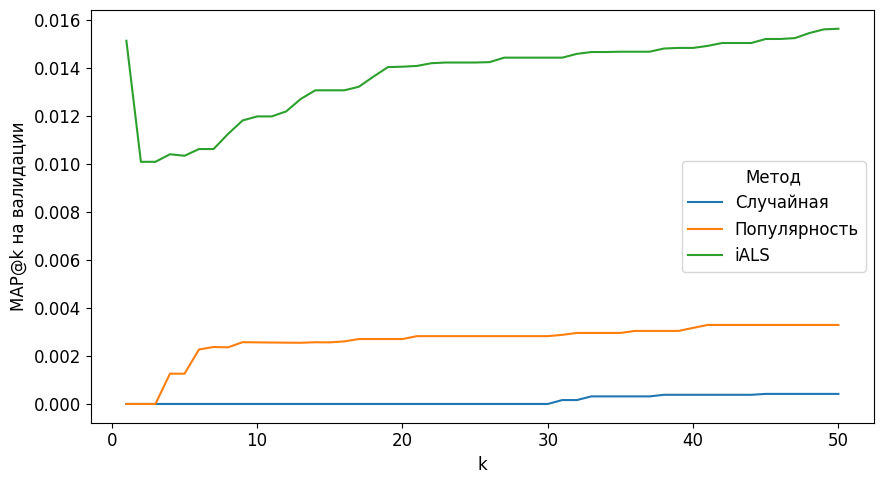

In [20]:
ks = np.arange(1, 51)
validation_predictions = {
    'Случайная': random_valid,
    'Популярность': top_valid,
    'iALS': best_predictions,
}

plt.figure(figsize=(9, 5))
for name, predictions in validation_predictions.items():
    values = [ranking_metrics(valid_relevant, predictions, k)[f'MAP@{k}'] for k in ks]
    plt.plot(ks, values, label=name)
plt.legend(title='Метод')
plt.xlabel('k')
plt.ylabel('MAP@k на валидации')
plt.tight_layout()
plt.show()

### Проверка на тесте

Параметры выбраны. Заново обучим iALS на всей истории до `valid_end`. Теперь в неё входят валидационный день и получасовой перерыв перед ним: для финальной модели это уже прошлое. Последние 30 минут перед тестом по-прежнему не используем. Для популярности возьмём ту же историю; каталог и соответствие идентификаторов оставим прежними.

Из выдачи и ответов исключим треки, уже лайкнутые в этой истории. Сравним три метода за тестовый день. Ни параметры, ни историю пользователя в течение этого дня не обновляем.

In [21]:
final_history = make_matrix(final_train_raw)
P, Q = ALS(final_history, **best_params)
test_relevant = make_relevant(test_raw, final_history)
test_users = np.array(sorted(test_relevant))
print(f'Пользователей для оценки на тесте: {len(test_users)} из {num_users}')

test_predictions = {
    'Случайная': random_prediction(final_history, test_users),
    'Популярность': top_prediction(final_history, test_users),
    'iALS': ALS_prediction(P, Q, final_history, test_users),
}
test_results = pd.DataFrame({
    name: ranking_metrics(test_relevant, predictions)
    for name, predictions in test_predictions.items()
}).T
test_results.round(5)

Пользователей для оценки на тесте: 194 из 2000


,MAP@20,Recall@20
Случайная,0.00007,0.00074
Популярность,0.00485,0.02674
iALS,0.00824,0.03708


### Насколько разнообразны рекомендации

Одной точности недостаточно. Посчитаем ещё *coverage* - долю каталога, которую модель хотя бы раз порекомендовала, и *personalization* - среднее косинусное расстояние между бинарными векторами выдачи разных пользователей.

Сравниваем тех же тестовых пользователей и списки длины до 20. Высокое разнообразие само по себе не означает полезных рекомендаций: случайный алгоритм тоже может показать большой охват.

In [22]:
def coverage(predictions, num_items):
    recommended = np.concatenate(list(predictions.values()))
    return len(np.unique(recommended)) / num_items


def personalization(predictions, num_items):
    lists = list(predictions.values())
    rows = np.repeat(np.arange(len(lists)), [len(items) for items in lists])
    cols = np.concatenate(lists)
    matrix = scs.csr_matrix(
        (np.ones(len(cols)), (rows, cols)), shape=(len(lists), num_items)
    )
    similarities = cosine_similarity(matrix)
    return np.mean(1 - similarities[np.triu_indices(len(lists), k=1)])

In [23]:
diversity_results = pd.DataFrame({
    name: {'Coverage@20': coverage(predictions, num_items),
           'Personalization@20': personalization(predictions, num_items)}
    for name, predictions in test_predictions.items()
}).T
test_results.join(diversity_results).round(5)

,MAP@20,Recall@20,Coverage@20,Personalization@20
Случайная,0.00007,0.00074,0.5388,0.99595
Популярность,0.00485,0.02674,0.0094,0.21085
iALS,0.00824,0.03708,0.2262,0.95496


### Похожие треки

Можно использовать векторы треков и для поиска похожих объектов. Возьмём популярный трек и найдём ближайшие к нему по косинусной близости. Сам трек из результата исключим.

Это близость по истории взаимодействий, не по аудио. В таблице будут только обезличенные идентификаторы; по ним нельзя проверить, насколько треки похожи по звучанию.

In [24]:
example_item = int(np.asarray(train_matrix.sum(axis=0)).ravel().argmax())
scores = cosine_similarity(Q[example_item:example_item + 1], Q).ravel()
scores[example_item] = -np.inf
similar_items = np.argsort(-scores, kind='stable')[:10]
print('Исходный item_id:', item_ids[example_item])
pd.DataFrame({
    'item_id': item_ids[similar_items],
    'Косинусная близость': scores[similar_items],
})

Исходный item_id: 3542184


,item_id,Косинусная близость
0,3385274,0.957660
1,8213481,0.947878
2,906358,0.903086
3,2651314,0.898552
4,7708302,0.885338
5,1846252,0.856188
6,9378983,0.853944
7,6901374,0.841267
8,5862961,0.836466
9,1981007,0.827437


### Что общего у соседних треков

В Yambda есть ещё две таблицы: соответствия треков исполнителям и альбомам. Все идентификаторы в них тоже обезличены. Названия песен мы не узнаем, зато сможем проверить, есть ли у найденных соседей общий исполнитель или альбом.

Подгрузим [эти таблицы](https://huggingface.co/datasets/yandex/yambda/tree/main) и оставим только наш каталог. У трека может быть несколько исполнителей или альбомов, поэтому сохраним все соответствия, а не только первое.

In [25]:
metadata_url = (
    'https://huggingface.co/datasets/yandex/yambda/resolve/'
    'c92027b889b5147d70ad10a3d8701c6f1d3f9952'
)
track_metadata = {}
for kind in ('artist', 'album'):
    column = f'{kind}_id'
    mapping = pd.read_parquet(
        f'{metadata_url}/{kind}_item_mapping.parquet', columns=['item_id', column]
    )
    mapping = mapping[mapping['item_id'].isin(item_ids)]
    track_metadata[kind] = (
        mapping.groupby('item_id')[column]
        .agg(lambda values: tuple(sorted(set(values.dropna())))).to_dict()
    )

Добавим к прежней таблице метаданные и число пользователей, лайкнувших оба трека. Лайки считаем по истории до теста и только среди пользователей нашего среза. Совпадение исполнителей означает, что есть хотя бы один общий исполнитель; с альбомами поступим так же. Пропуск в столбце совпадений означает, что для сравнения не хватает метаданных.

Эти сведения не участвовали в обучении iALS. Посмотрим, согласуется ли близость по взаимодействиям со связями между треками.

In [26]:
nearby_indices = np.r_[example_item, similar_items]
nearby = pd.DataFrame({
    'item_id': item_ids[nearby_indices],
    'Близость iALS': cosine_similarity(
        Q[nearby_indices], Q[example_item:example_item + 1]
    ).ravel(),
}, index=['Исходный'] + [f'Сосед {i}' for i in range(1, len(similar_items) + 1)])

for kind, title, common_title in (
    ('artist', 'Исполнители (ID)', 'Общий исполнитель'),
    ('album', 'Альбомы (ID)', 'Общий альбом'),
):
    nearby[title] = [track_metadata[kind].get(int(item), ()) for item in nearby['item_id']]
    reference = set(nearby.iloc[0][title])
    nearby[common_title] = pd.array([
        bool(reference.intersection(ids)) if reference and ids else pd.NA
        for ids in nearby[title]
    ], dtype='boolean')

liked = final_history[:, nearby_indices].toarray().astype(bool)
nearby['Лайков до теста'] = liked.sum(axis=0)
nearby['Лайкнули оба трека'] = (liked & liked[:, [0]]).sum(axis=0)
nearby.round({'Близость iALS': 4})

,item_id,Близость iALS,Исполнители (ID),Общий исполнитель,Альбомы (ID),Общий альбом,Лайков до теста,Лайкнули оба трека
Исходный,3542184,1.0000,"(45800,)",True,"(151119, 1362653)",True,278,278
Сосед 1,3385274,0.9577,"(601309,)",False,"(1646906,)",False,135,74
Сосед 2,8213481,0.9479,"(899541,)",False,"(1614382,)",False,171,89
Сосед 3,906358,0.9031,"(1278021,)",False,"(1821795,)",False,224,86
Сосед 4,2651314,0.8986,"(731408,)",False,"(840140, 1667792)",False,148,69
Сосед 5,7708302,0.8853,"(163533,)",False,"(1066374,)",False,62,26
Сосед 6,1846252,0.8562,"(91874,)",False,"(2367871,)",False,190,62
Сосед 7,9378983,0.8539,"(792320,)",False,"(942400,)",False,250,72
Сосед 8,6901374,0.8413,"(1077200,)",False,"(1207039, 2030558)",False,254,85
Сосед 9,5862961,0.8365,"(605225,)",False,"(865998,)",False,236,77


Посмотрите на соседей: есть ли общие исполнители или альбомы? Похожая аудитория не обязательно слушает только одного исполнителя.

Косинусная близость 0.95 здесь не означает "95% вероятности, что треки похожи". Мы сравниваем направления векторов, обученных по лайкам, а не звучание записей.

Обошла ли iALS рекомендации по популярности? Что при этом произошло с охватом каталога и различиями между пользовательскими списками? Ответы могут зависеть не только от модели, но и от того, какие треки мы оставили в срезе.

## Пример с MovieLens

Так как в наборе яндекса мы не смогли вытащить метаинформацию, посмотрим на классику - [MovieLens](https://files.grouplens.org/datasets/movielens/ml-latest-small-README.html). Здесь есть и оценки от 0.5 до 5, и названия, и жанры фильмов.

Это отдельный пример, поэтому обучим модель для числовых рейтингов и посмотрим, какие фильмы окажутся рядом в пространстве скрытых представлений. Жанры и названия при обучении использовать не будем.

In [33]:
from io import BytesIO
from zipfile import ZipFile
from urllib.request import urlopen
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

ml_url = 'https://files.grouplens.org/datasets/movielens/ml-latest-small.zip'
with urlopen(ml_url) as response, ZipFile(BytesIO(response.read())) as archive:
    ml_ratings = pd.read_csv(archive.open('ml-latest-small/ratings.csv'))
    ml_movies = pd.read_csv(archive.open('ml-latest-small/movies.csv'))

ml_ratings.merge(ml_movies, on='movieId').head()

,userId,movieId,rating,timestamp,title,genres
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


Здесь решаем задачу восстановления оценок: случайно отложим 20% известных рейтингов, а на остальных обучим модель. Для оценки оставим только пользователей и фильмы, встретившиеся в обучении.

> Но это не проверка будущих действий, как мы делали с вами на Yambda.

In [28]:
ml_train, ml_test = train_test_split(ml_ratings, test_size=0.2, random_state=SEED)
ml_user_ids = np.sort(ml_train['userId'].unique())
ml_item_ids = np.sort(ml_train['movieId'].unique())
ml_user_index = pd.Series(np.arange(len(ml_user_ids)), index=ml_user_ids)
ml_item_index = pd.Series(np.arange(len(ml_item_ids)), index=ml_item_ids)

known = ml_test['userId'].isin(ml_user_ids) & ml_test['movieId'].isin(ml_item_ids)
print(f'На тесте оставлено {known.sum()} из {len(ml_test)} оценок: известные пользователи и фильмы.')
ml_test = ml_test.loc[known].copy()
ml_catalog = ml_movies.set_index('movieId').loc[ml_item_ids].reset_index()

ml_matrix = scs.csr_matrix((
    ml_train['rating'].to_numpy(),
    (ml_train['userId'].map(ml_user_index), ml_train['movieId'].map(ml_item_index)),
), shape=(len(ml_user_ids), len(ml_item_ids)))

На тесте оставлено 19355 из 20168 оценок: известные пользователи и фильмы.


Посмотрим на распределение оценок на обучении. В отличие от лайков, здесь есть и низкие, и высокие значения. Какие оценки встречаются чаще? Что предсказывала бы модель, которая совсем не учитывает пользователя и фильм?

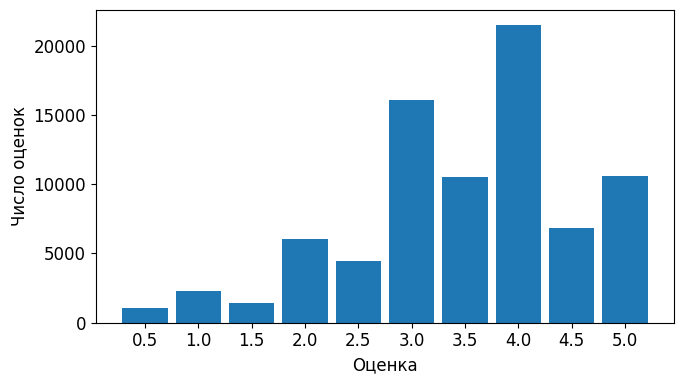

In [29]:
plt.figure(figsize=(7, 4))
plt.hist(ml_train['rating'], bins=np.arange(0.25, 5.26, 0.5), rwidth=0.85)
plt.xticks(np.arange(0.5, 5.1, 0.5))
plt.xlabel('Оценка')
plt.ylabel('Число оценок')
plt.tight_layout()
plt.show()

### ALS для числовых оценок

Представим рейтинг как среднюю оценку $\mu$ плюс скалярное произведение векторов пользователя и фильма. Среднее считаем только на обучении:

$$
\sum_{(u,i)\in\Omega}(r_{ui}-\mu-p_u^Tq_i)^2
+\lambda\left(\sum_u\|p_u\|^2+\sum_i\|q_i\|^2\right)\longrightarrow\min_{P,Q}.
$$

Здесь $\Omega$ - пары с известным рейтингом. В отличие от iALS, отсутствующие оценки в сумму не входят. Фиксируя векторы фильмов, решаем отдельную систему линейных уравнений для каждого пользователя, затем наоборот.

In [30]:
def explicit_ALS(R, num_dims=16, regularization=1.0, num_iters=10):
    R = R.tocsr()
    RT = R.T.tocsr()
    mean_rating = R.data.mean()
    rng = np.random.default_rng(SEED)
    P = rng.normal(scale=0.1, size=(R.shape[0], num_dims))
    Q = rng.normal(scale=0.1, size=(R.shape[1], num_dims))
    penalty = regularization * np.eye(num_dims)

    with threadpool_limits(limits=1, user_api='blas'):
        for _ in range(num_iters):
            for u in range(R.shape[0]):
                start, end = R.indptr[u:u + 2]
                factors = Q[R.indices[start:end]]
                values = R.data[start:end] - mean_rating
                P[u] = np.linalg.solve(factors.T @ factors + penalty, factors.T @ values)
            for i in range(RT.shape[0]):
                start, end = RT.indptr[i:i + 2]
                factors = P[RT.indices[start:end]]
                values = RT.data[start:end] - mean_rating
                Q[i] = np.linalg.solve(factors.T @ factors + penalty, factors.T @ values)
    return mean_rating, P, Q


ml_mean, ml_P, ml_Q = explicit_ALS(ml_matrix)

Сравним качество восстановления рейтингов на обучении и тесте. В качестве простого ориентира возьмём среднюю обучающую оценку. Насколько различаются результаты на обучении и тесте? Стало ли лучше, чем у константной модели?

In [31]:
def predict_ratings(events):
    users = events['userId'].map(ml_user_index).to_numpy()
    items = events['movieId'].map(ml_item_index).to_numpy()
    return ml_mean + (ml_P[users] * ml_Q[items]).sum(axis=1)


print(f"Train R^2: {r2_score(ml_train['rating'], predict_ratings(ml_train)):.3f}")
print(f"Test R^2: {r2_score(ml_test['rating'], predict_ratings(ml_test)):.3f}")
print(f"Test R^2 средней оценки: {r2_score(ml_test['rating'], np.full(len(ml_test), ml_mean)):.3f}")

Train R^2: 0.862
Test R^2: -0.075
Test R^2 средней оценки: -0.000


### Похожие фильмы

Возьмем Железного человека и найдём ближайшие фильмы по косинусной близости их векторов. Среди кандидатов оставим фильмы хотя бы с десятью оценками на обучении: вектор фильма с одной оценкой слишком ненадёжен.

In [32]:
movie_title = 'Iron Man (2008)'
ml_example = np.flatnonzero(ml_catalog['title'].eq(movie_title))[0]
ml_counts = np.diff(ml_matrix.tocsc().indptr)
ml_scores = cosine_similarity(ml_Q[ml_example:ml_example + 1], ml_Q).ravel()
ml_scores[ml_counts < 10] = -np.inf
ml_scores[ml_example] = -np.inf
ml_neighbours = np.argsort(-ml_scores, kind='stable')[:10]
ml_neighbours = ml_neighbours[np.isfinite(ml_scores[ml_neighbours])]

print('Исходный фильм:', movie_title)
movie_neighbours = ml_catalog.iloc[ml_neighbours][['title', 'genres']].copy()
movie_neighbours.columns = ['Фильм', 'Жанры']
movie_neighbours['Косинусная близость'] = ml_scores[ml_neighbours]
movie_neighbours['Оценок на обучении'] = ml_counts[ml_neighbours]
movie_neighbours.reset_index(drop=True).round({'Косинусная близость': 3})

Исходный фильм: Iron Man (2008)


,Фильм,Жанры,Косинусная близость,Оценок на обучении
0,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,0.802,146
1,Zootopia (2016),Action|Adventure|Animation|Children|Comedy,0.769,30
2,Guardians of the Galaxy (2014),Action|Adventure|Sci-Fi,0.744,46
3,Say Anything... (1989),Comedy|Drama|Romance,0.712,32
4,WALL·E (2008),Adventure|Animation|Children|Romance|Sci-Fi,0.705,84
5,My Neighbor Totoro (Tonari no Totoro) (1988),Animation|Children|Drama|Fantasy,0.701,28
6,Birdman: Or (The Unexpected Virtue of Ignoranc...,Comedy|Drama,0.698,23
7,Tangled (2010),Animation|Children|Comedy|Fantasy|Musical|Roma...,0.693,18
8,"Dark Knight Rises, The (2012)",Action|Adventure|Crime|IMAX,0.681,68
9,"Avengers, The (2012)",Action|Adventure|Sci-Fi|IMAX,0.674,59


Какие соседи кажутся ожидаемыми, а какие удивляют? Совпадение жанров не обязательно: модель видела только оценки и могла найти общую аудиторию у разных по содержанию фильмов.

Хорошее восстановление рейтингов, хорошие рекомендации и понятные человеку соседи - не одно и то же. Здесь мы посмотрели на первый и третий вопросы, а для второго нужна отдельная проверка ранжирования, как в музыкальном примере.